# MetricSuite 8 -- Recipe: a statistics revision plan, request by request

Reviewers often ask for the same set of things: a stricter correction, effects with
intervals, non-inferiority instead of "no significant difference", a proper
treatment of ties and binary outcomes, curves compared without over-interpreting
clusters, and bootstrap intervals for quantities computed from resampled data.

This notebook goes through such a plan -- five comparisons -- with the shortest code
that answers each request, on fake data. Each step links back to the tutorial that
explains it. Use it as a checklist when writing the methods section.

| # | comparison | requests | tutorial |
|---|---|---|---|
| 0 | all | Holm; effects in units with CI + a standardized one; Kerby r | 3, 4 |
| 1 | localization error | non-inferiority with δ, Pratt, HL CI, Holm | 4 |
| 2 | correlation over time | window mean; cluster test in the window, Holm across pairs; difference curve; bootstrap CI | 6, 7 |
| 3 | surrogate connectomes | non-inferiority per outcome, Holm per outcome; benchmarks as description | 4 |
| 4 | distance to resection | Wilcoxon with Pratt; exact McNemar; Newcombe Δp; counts | 4, 5 |
| 5 | virtual iEEG | spike bootstrap per subject, Holm per subject | 6 |

In [1]:
import tempfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mindmap.metric import MetricSuite

warnings.filterwarnings("ignore", message="No clusters found")
COLORS = {"wCSET": "#2a78d6", "CSET": "#1baf7a", "dSPM": "#e34948", "sLORETA": "#f0a020", "MNE": "#8c5bd6"}
COMPETITORS = ["CSET", "dSPM", "sLORETA", "MNE"]
rng = np.random.default_rng(2026)
results = {}          # every result that goes in the paper, saved at the end

## 0 - General rules

Decided once, applied everywhere:

- **Holm** within each family (`correction="holm"`). A family = one call: e.g.
  "wCSET vs its 4 competitors on one outcome".
- Every test reports an **unstandardized effect in the metric's units** and a
  **standardized** one (`effect_sizes=`), each **with its 95% interval** -- the
  tests add them by default (`<name>_ci_low`/`_ci_high`).
- The Wilcoxon effect size is the **matched-pairs rank-biserial** (Kerby 2014) --
  the suite's `rank_biserial`.

## 1 - Localization error: non-inferiority

*Request: test non-inferiority of wCSET against each competitor with a margin δ,
plus the two-sided test; Wilcoxon with Pratt; HL with 95% CI read against δ; Holm.*

In [2]:
study = MetricSuite(name="Study I")
TRUE_ERROR = {"wCSET": 10.0, "CSET": 10.3, "dSPM": 15.0, "sLORETA": 13.5, "MNE": 16.0}
for r in range(100):                                          # 100 simulated regions
    difficulty = rng.gamma(2.0, 3.0)
    for method, mu in TRUE_ERROR.items():
        err = max(mu + difficulty + rng.normal(0, 2.0), 0.0)
        study.register("loc_error_mm", round(err, 1), method=method, region=f"R{r:03d}")

DELTA = 1.0                                                   # mm, fixed before the analysis
comparisons = study.stat.build_comparisons("wCSET", COMPETITORS)
common = dict(group_by="method", comparisons=comparisons, pairing_col="region", zero_method="pratt",
              correction="holm", effect_sizes=("rank_biserial", "hodges_lehmann"))

# lower is better: wCSET - competitor < δ  <=>  "wCSET is not worse by δ or more"
results["loc_noninferiority"] = study.stat.wilcoxon("loc_error_mm", offset=DELTA, alternative="less", **common)
results["loc_twosided"] = study.stat.wilcoxon("loc_error_mm", **common)
summary = results["loc_noninferiority"].vs("wCSET", higher_is_better=False)[
    ["p_corrected", "hodges_lehmann", "hodges_lehmann_ci_low", "hodges_lehmann_ci_high", "rank_biserial", "n_zero"]
].rename(columns={"p_corrected": "p non-inferiority"})
summary.insert(1, "p two-sided", results["loc_twosided"].vs("wCSET", higher_is_better=False)["p_corrected"])
summary

,p non-inferiority,p two-sided,hodges_lehmann,hodges_lehmann_ci_low,hodges_lehmann_ci_high,rank_biserial,n_zero
method,,,,,,,
CSET,8.493295e-07,7.050232e-02,0.60,-0.05,1.20,0.208317,0
dSPM,1.334978e-17,1.245092e-16,5.30,4.65,5.95,0.968515,0
sLORETA,5.644093e-17,4.517871e-14,3.40,2.75,4.05,0.879406,1
MNE,9.908742e-18,3.205275e-17,6.15,5.45,6.75,0.990495,0


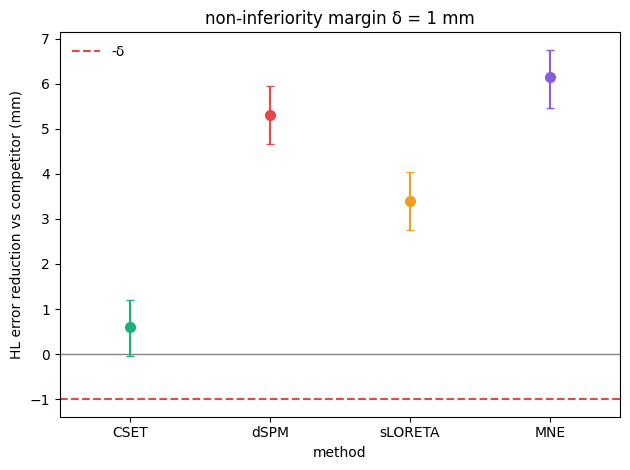

In [3]:
results["loc_hl"] = study.estimate.from_result(results["loc_twosided"])     # an EstimateResult, for plot.estimate
fig, ax = study.plot.estimate(results["loc_hl"], reference="wCSET", higher_is_better=False, palette=COLORS,
                              reference_lines={"-δ": (-DELTA, "#e34948")},
                              ylabel="HL error reduction vs competitor (mm)", title="non-inferiority margin δ = 1 mm")
ax.legend(frameon=False)
fig.tight_layout()

Reading: non-inferior where the whole interval lies above -δ; superior where it
also excludes 0. (Tutorial 4, Part 4.)

## 2 - Correlation over time: window, clusters, difference curve

*Requests: a pre-specified window; the window-mean test as primary; a cluster test
restricted to the window with Holm across the 4 pairs on each pair's smallest
cluster p; a difference curve with a CI band; no claim on cluster timing; a
bootstrap CI for the window effect.*

In [4]:
TIMES = np.round(np.linspace(-0.05, 0.15, 41), 3)
peak = np.exp(-((TIMES - 0.03) / 0.03) ** 2)
GAIN = {"wCSET": 0.10, "CSET": 0.09, "dSPM": 0.0, "sLORETA": 0.03, "MNE": 0.01}
for r in range(100):
    base = 0.3 + 0.4 * peak + rng.normal(0, 0.05)
    for method, gain in GAIN.items():
        study.register("correlation", base + gain * peak + rng.normal(0, 0.06, TIMES.size),
                       method=method, region=f"R{r:03d}", times=TIMES)

window = {"times": [t for t in TIMES if 0.0 <= t <= 0.08]}   # pre-specified: 0-80 ms
corr = dict(group_by="method", comparisons=comparisons, pairing_col="region", filters=window, correction="holm")

results["corr_window"] = study.stat.wilcoxon("correlation", effect_sizes=("rank_biserial", "hodges_lehmann"), **corr)
results["corr_window_boot"] = study.estimate.mean_diff("correlation", "method", comparisons, pairing_col="region",
                                                       filters=window, ci_method="bootstrap", seed=1)
results["corr_clusters"] = study.stat.cluster_permutation("correlation", coord="times", family="pair",
                                                          n_permutations=5000, seed=0, **corr)

results["corr_window"].vs("wCSET")[["p_corrected", "rank_biserial", "hodges_lehmann", "hodges_lehmann_ci_low",
                                    "hodges_lehmann_ci_high"]].join(
    results["corr_window_boot"].vs("wCSET")[["estimate", "ci_low", "ci_high"]].add_prefix("Δmean, bootstrap ")).join(
    results["corr_clusters"].pair_table.set_index("group_b")[["n_clusters", "p_corrected"]].add_prefix("cluster "))

,p_corrected,rank_biserial,hodges_lehmann,hodges_lehmann_ci_low,hodges_lehmann_ci_high,"Δmean, bootstrap estimate","Δmean, bootstrap ci_low","Δmean, bootstrap ci_high",cluster n_clusters,cluster p_corrected
method,,,,,,,,,,
CSET,2.542318e-02,0.257426,0.004148,0.000464,0.008275,0.005485,0.001859,0.009218,2,0.0170
dSPM,1.558624e-17,1.000000,0.057471,0.053672,0.061540,0.057962,0.054047,0.061864,1,0.0008
sLORETA,1.558624e-17,0.997624,0.039031,0.034786,0.043359,0.039931,0.035776,0.044159,1,0.0008
MNE,1.558624e-17,1.000000,0.053234,0.049555,0.056870,0.052798,0.049216,0.056356,1,0.0008


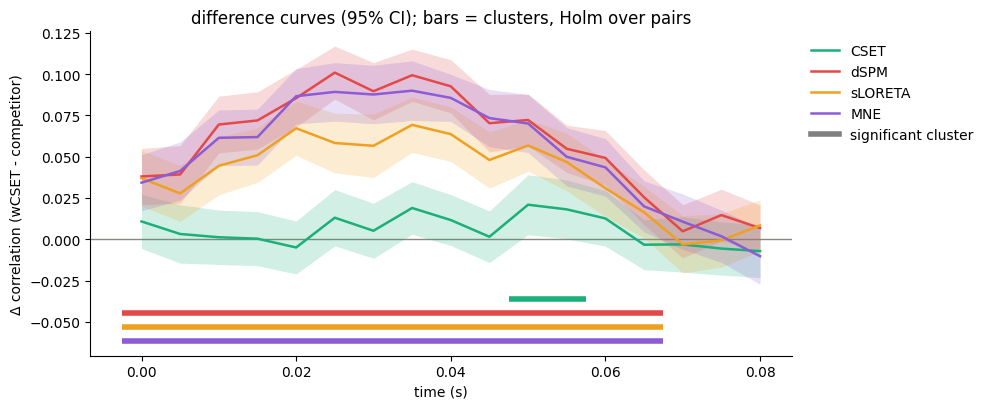

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
study.plot.paired_differences(results["corr_clusters"], palette=COLORS, xlabel="time (s)", ax=ax,
                              ylabel="Δ correlation (wCSET - competitor)",
                              legend="outside", title="difference curves (95% CI); bars = clusters, Holm over pairs")
fig.tight_layout()

Wording for the paper: "wCSET's correlation differed from that of X within the
0-80 ms window (cluster permutation, Holm across the four comparisons)" -- not
"from 15 to 55 ms". The size is the window-mean effect, not the cluster-mean d.
(Tutorial 7.)

## 3 - Surrogate connectomes: non-inferiority per outcome

*Request: is wCSET with a surrogate connectome not worse than with the true one, on
each main outcome? Holm within each outcome; external benchmarks drawn as
descriptive lines only.*

In [6]:
SURROGATES = ["shuffled", "distance", "random"]
for r in range(100):
    base_err, base_corr = rng.gamma(2.0, 3.0) + 10, rng.normal(0.7, 0.05)
    for connectome, loss in [("true", 0.0), ("shuffled", 0.3), ("distance", 0.2), ("random", 1.5)]:
        study.register("surrogate_error_mm", base_err + loss + rng.normal(0, 1.5), connectome=connectome, region=f"R{r:03d}")
        study.register("surrogate_correlation", base_corr - loss / 30 + rng.normal(0, 0.02),
                       connectome=connectome, region=f"R{r:03d}")

OUTCOMES = {"surrogate_error_mm": (1.0, False), "surrogate_correlation": (0.02, True)}   # (δ, higher is better)
surr_pairs = study.stat.build_comparisons(SURROGATES, "true")
rows = {}
for outcome, (delta, higher) in OUTCOMES.items():
    # surrogate - true must stay above -δ (higher is better) or below +δ (lower is better)
    res = study.stat.wilcoxon(outcome, "connectome", surr_pairs, pairing_col="region", zero_method="pratt",
                              offset=-delta if higher else delta, alternative="greater" if higher else "less",
                              correction="holm", effect_sizes=("rank_biserial", "hodges_lehmann"))
    results[f"{outcome}_noninferiority"] = res
    rows[outcome] = res.table.set_index("group_a")[
        ["p_corrected", "hodges_lehmann", "hodges_lehmann_ci_low", "hodges_lehmann_ci_high"]].assign(δ=delta)
pd.concat(rows)

p_corrected  hodges_lehmann  \
                      group_a                                  
surrogate_error_mm    shuffled  1.616329e-03        0.271624   
                      distance  9.473079e-04        0.213547   
                      random    9.847181e-01        1.455371   
surrogate_correlation shuffled  1.471025e-04       -0.008286   
                      distance  3.424549e-07       -0.004532   
                      random    1.000000e+00       -0.046012   

                                hodges_lehmann_ci_low  hodges_lehmann_ci_high  \
                      group_a                                                   
surrogate_error_mm    shuffled              -0.188099                0.701063   
                      distance              -0.233452                0.656794   
                      random                 1.038126                1.834087   
surrogate_correlation shuffled              -0.014017               -0.002862   
                      distance              -0.010256                0.001216   
                      random                -0.051805               -0.040408   

                                   δ  
                      group_a         
surrogate_error_mm    shuffled  1.00  
                      distance  1.00  
                      random    1.00  
surrogate_correlation shuffled  0.02  
                      distance  0.02  
                      random    0.02

Each outcome is its own Holm family (one call per outcome). Benchmarks such as
"1.x times dSPM's error" are external numbers: draw them with
`reference_lines={"dSPM benchmark": value}`, and don't test against them.
(Tutorial 4, Part 4.)

## 4 - Distance to resection: continuous and binary

*Requests: Wilcoxon with Pratt (many zeros); exact McNemar on "inside the
resection"; Δ proportion with a Newcombe CI; report the discordant counts; Holm.*

In [7]:
study2 = MetricSuite(name="Study II")
SKILL = {"wCSET": 0.9, "CSET": 0.5, "dSPM": -0.5, "sLORETA": -0.2, "MNE": -0.6}
for p in range(40):
    difficulty = rng.normal(0, 1.5)
    for method, skill in SKILL.items():
        inside = rng.random() < 1 / (1 + np.exp(-(skill - difficulty)))
        distance = 0.0 if inside else rng.gamma(2.0, 6.0)
        study2.register("distance_mm", distance, method=method, patient=f"P{p:02d}")
        study2.register("inside", float(inside), method=method, patient=f"P{p:02d}")

pairs2 = study2.stat.build_comparisons("wCSET", COMPETITORS)
results["distance"] = study2.stat.wilcoxon("distance_mm", "method", pairs2, pairing_col="patient", zero_method="pratt",
                                           correction="holm", effect_sizes=("rank_biserial", "hodges_lehmann"))
results["inside"] = study2.stat.mcnemar("inside", "method", pairs2, pairing_col="patient", correction="holm",
                                        effect_sizes=("prop_diff", "odds_ratio"))

dist = results["distance"].vs("wCSET", higher_is_better=False)[["p_corrected", "rank_biserial", "n_zero"]].add_prefix("distance ")
ins = results["inside"].vs("wCSET")[["p_corrected", "n_reference_only", "n_competitor_only", "prop_diff",
                                     "prop_diff_ci_low", "prop_diff_ci_high"]].add_prefix("McNemar ")
dist.join(ins)

,distance p_corrected,distance rank_biserial,distance n_zero,McNemar p_corrected,McNemar n_reference_only,McNemar n_competitor_only,McNemar prop_diff,McNemar prop_diff_ci_low,McNemar prop_diff_ci_high
method,,,,,,,,,
CSET,0.685797,0.065854,23,1.000000,6,6,0.000,-0.173297,0.173297
dSPM,0.007217,0.528049,17,0.025879,12,2,0.250,0.071210,0.405087
sLORETA,0.157851,0.309756,15,0.012543,14,2,0.300,0.111912,0.457159
MNE,0.001456,0.643902,8,0.000004,21,0,0.525,0.339194,0.654816


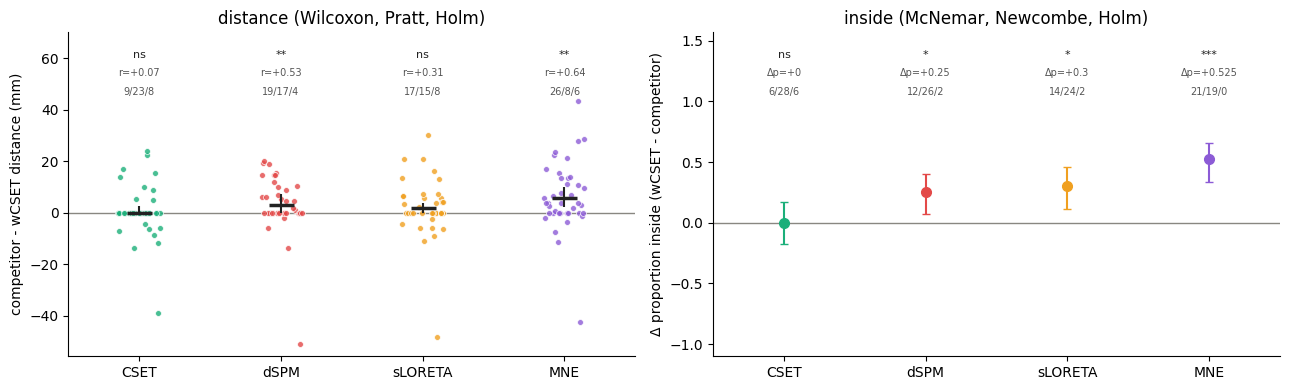

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
study2.plot.paired_differences(results["distance"], higher_is_better=False, palette=COLORS, kind="strip", ax=axes[0],
                               annotate=("stars", "effect", "counts"), ylabel="competitor - wCSET distance (mm)",
                               title="distance (Wilcoxon, Pratt, Holm)")
study2.plot.paired_differences(results["inside"], palette=COLORS, ax=axes[1], annotate=("stars", "prop_diff", "counts"),
                               ylabel="Δ proportion inside (wCSET - competitor)", title="inside (McNemar, Newcombe, Holm)")
fig.tight_layout()

(Tutorial 4, Part 5 and tutorial 5.)

## 5 - Virtual iEEG: spike bootstrap per subject

*Request: Δρ per subject with a 95% bootstrap interval over spikes (paired: same
resample for every method), a bootstrap p-value, Holm across competitors within each
subject; the share of timepoints where wCSET is higher as description only.*

The resampling happens in the pipeline (re-average the resampled spikes, re-run the
inverse, recompute ρ); the suite reads the draws. Here a stand-in pipeline produces
them directly:

In [9]:
study3 = MetricSuite(name="Study III")
B = 2000
for subject in ["S1", "S2", "S3", "S4"]:
    rho_true = {"wCSET": 0.75, "CSET": 0.70, "dSPM": 0.62, "sLORETA": 0.66, "MNE": 0.60}
    shared = rng.normal(0, 0.04, B)                             # same spike resample for every method
    for method, rho in rho_true.items():
        observed = rho + rng.normal(0, 0.03)
        study3.register("rho", observed, method=method, subject=subject)
        study3.register("rho_boot", observed + shared + rng.normal(0, 0.015, B), method=method, subject=subject,
                        boot=np.arange(B))

per_subject = {}
for subject in ["S1", "S2", "S3", "S4"]:
    res = study3.stat.bootstrap("rho", "method", comparisons, pairing_col="subject", replicates="rho_boot",
                                replicate_col="boot", filters={"subject": subject}, correction="holm")
    results[f"vieeg_{subject}"] = res
    per_subject[subject] = res.vs("wCSET")[["mean_diff", "mean_diff_ci_low", "mean_diff_ci_high", "p_corrected"]]
pd.concat(per_subject).round(4)

mean_diff  mean_diff_ci_low  mean_diff_ci_high  p_corrected
   method                                                              
S1 CSET        0.0632            0.0206             0.1088       0.0040
   dSPM        0.0924            0.0515             0.1349       0.0040
   sLORETA     0.0943            0.0524             0.1363       0.0040
   MNE         0.1851            0.1436             0.2271       0.0040
S2 CSET       -0.0205           -0.0611             0.0191       0.6837
   dSPM        0.0562            0.0139             0.0990       0.0240
   sLORETA     0.0511            0.0103             0.0912       0.0390
   MNE         0.0170           -0.0248             0.0602       0.6837
S3 CSET        0.0067           -0.0331             0.0475       0.7496
   dSPM        0.0928            0.0518             0.1353       0.0040
   sLORETA     0.0473            0.0027             0.0900       0.0740
   MNE         0.0696            0.0271             0.1123       0.0060
S4 CSET        0.0542            0.0119             0.0974       0.0090
   dSPM        0.1539            0.1119             0.1972       0.0040
   sLORETA     0.0758            0.0321             0.1166       0.0040
   MNE         0.1816            0.1393             0.2234       0.0040

(Tutorial 6, Part 4.) The share of timepoints where wCSET's virtual iEEG beats the
competitor is descriptive: compute it in the pipeline, or with
`annotate=("winrate",)` on a paired-differences plot over timepoints -- don't test
it as if timepoints were independent.

## 💾 - Keeping the results

Save every result that enters the paper, with the data it came from. Each result
carries its settings and a fingerprint of its data, so the numbers in the paper can
always be traced and checked:

In [10]:
workdir = Path(tempfile.mkdtemp())
for suite in (study, study2, study3):
    suite.save(workdir / suite.name.replace(" ", "_"))
for name, result in results.items():
    result.save(workdir / "results" / name)
sorted(p.name for p in (workdir / "results").iterdir())

MetricSuite successfully saved to folder: /tmp/tmpga7ynrth/Study_I
MetricSuite successfully saved to folder: /tmp/tmpga7ynrth/Study_II
MetricSuite successfully saved to folder: /tmp/tmpga7ynrth/Study_III


['corr_clusters',
 'corr_window',
 'corr_window_boot',
 'distance',
 'inside',
 'loc_hl',
 'loc_noninferiority',
 'loc_twosided',
 'surrogate_correlation_noninferiority',
 'surrogate_error_mm_noninferiority',
 'vieeg_S1',
 'vieeg_S2',
 'vieeg_S3',
 'vieeg_S4']

In [11]:
owner = {name: next(s for s in (study, study2, study3) if s.verify(r)).name for name, r in results.items()}
pd.Series(owner, name="verified against")

loc_noninferiority                        Study I
loc_twosided                              Study I
loc_hl                                    Study I
corr_window                               Study I
corr_window_boot                          Study I
corr_clusters                             Study I
surrogate_error_mm_noninferiority         Study I
surrogate_correlation_noninferiority      Study I
distance                                 Study II
inside                                   Study II
vieeg_S1                                Study III
vieeg_S2                                Study III
vieeg_S3                                Study III
vieeg_S4                                Study III
Name: verified against, dtype: object

## Checklist

| request | how |
|---|---|
| Holm everywhere | `correction="holm"`; one call = one family |
| effect in units + CI | in every test result: `<name>_ci_low`/`_ci_high` (HL, mean diff, Δp) |
| standardized effect + CI | `effect_sizes=("rank_biserial", ...)` (Kerby r), `cohens_dz`, odds ratio; bootstrap CI |
| non-inferiority | `offset=δ` + `alternative`; HL CI against δ; `plot.estimate(reference_lines=...)` |
| ties | `zero_method="pratt"`; report `n_zero` |
| binary outcome | `stat.mcnemar`; `estimate.prop_diff` (Newcombe); `n_reference_only` / `n_competitor_only` |
| window effect | any paired test with `filters={"times": window}`; bootstrap CI with `ci_method="bootstrap"` |
| clusters across pairs | `cluster_permutation(..., filters=window, correction="holm", family="pair")`; `pair_table` |
| difference curve | `plot.paired_differences(cluster_result)` |
| spike bootstrap | pipeline draws -> `replicates=` / `replicate_col=`; `stat.bootstrap` per subject |
| traceability | `result.save`, `suite.save`, `suite.verify(result)` |

What stays outside the suite: choosing δ and the primary outcomes **before** the
analysis, the resampling loop itself, and the wording -- clusters show *that* two
methods differ in a window, not exactly *when*.